<a href="https://colab.research.google.com/github/adityasptra14/supply-chain-delivery-analysis/blob/main/Supply_Chain_and_Delivery_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
np.random.seed(2026)

# Membuat 4.500 data pengiriman barang
n_shipments = 4500

warehouses = np.random.choice(
    ['Hub Jakarta', 'Hub Surabaya', 'Hub Medan', 'Hub Makassar'],
    size=n_shipments, p=[0.40, 0.30, 0.18, 0.12]
)
couriers = np.random.choice(
    ['Express Prioritas', 'Reguler Standar', 'Kargo Ekonomi'],
    size=n_shipments, p=[0.25, 0.55, 0.20]
)

# Simulasi waktu pemrosesan di gudang (jam) dan waktu pengiriman di jalan (hari)
warehouse_prep_days = []
transit_days = []
sla_target_days = []
shipping_cost = []

for w, c in zip(warehouses, couriers):
    # Target SLA berdasarkan layanan kurir
    if c == 'Express Prioritas':
        sla = 2
        cost = np.random.randint(25000, 45000)
        t_days = np.random.choice([1, 2, 3], p=[0.55, 0.35, 0.10])
    elif c == 'Reguler Standar':
        sla = 4
        cost = np.random.randint(12000, 24000)
        t_days = np.random.choice([2, 3, 4, 5], p=[0.30, 0.40, 0.20, 0.10])
    else:
        sla = 7
        cost = np.random.randint(8000, 15000)
        t_days = np.random.choice([4, 5, 6, 7, 8], p=[0.20, 0.30, 0.25, 0.15, 0.10])

    # Simulasi bottleneck (antrean pengemasan) di Hub Medan dan Makassar
    if w in ['Hub Medan', 'Hub Makassar']:
        prep = np.random.choice([0.5, 1.0, 2.0, 3.0], p=[0.20, 0.30, 0.35, 0.15])
    else:
        prep = np.random.choice([0.5, 1.0, 1.5], p=[0.60, 0.30, 0.10])

    warehouse_prep_days.append(prep)
    transit_days.append(t_days)
    sla_target_days.append(sla)
    shipping_cost.append(cost)

df_logistics = pd.DataFrame({
    'Shipment_ID': [f'SHP-{50000 + i}' for i in range(n_shipments)],
    'Origin_Hub': warehouses,
    'Courier_Service': couriers,
    'Warehouse_Prep_Days': warehouse_prep_days,
    'Transit_Days': transit_days,
    'SLA_Target_Days': sla_target_days,
    'Shipping_Cost_IDR': shipping_cost
})

# Menghitung Total Lead Time dan Status Keterlambatan (SLA Status)
df_logistics['Total_Lead_Time_Days'] = df_logistics['Warehouse_Prep_Days'] + df_logistics['Transit_Days']
df_logistics['Delay_Days'] = df_logistics['Total_Lead_Time_Days'] - df_logistics['SLA_Target_Days']
df_logistics['Delivery_Status'] = np.where(df_logistics['Total_Lead_Time_Days'] <= df_logistics['SLA_Target_Days'], 'On-Time', 'Delayed (Terlambat)')

print(f"Dataset Logistik siap dianalisis: {df_logistics.shape[0]} pengiriman.")
df_logistics.head()

Dataset Logistik siap dianalisis: 4500 pengiriman.


,Shipment_ID,Origin_Hub,Courier_Service,Warehouse_Prep_Days,Transit_Days,SLA_Target_Days,Shipping_Cost_IDR,Total_Lead_Time_Days,Delay_Days,Delivery_Status
0,SHP-50000,Hub Jakarta,Kargo Ekonomi,0.5,6,7,9455,6.5,-0.5,On-Time
1,SHP-50001,Hub Surabaya,Kargo Ekonomi,0.5,7,7,8524,7.5,0.5,Delayed (Terlambat)
2,SHP-50002,Hub Makassar,Reguler Standar,1.0,5,4,21857,6.0,2.0,Delayed (Terlambat)
3,SHP-50003,Hub Jakarta,Reguler Standar,0.5,3,4,21016,3.5,-0.5,On-Time
4,SHP-50004,Hub Surabaya,Kargo Ekonomi,1.0,5,7,9658,6.0,-1.0,On-Time


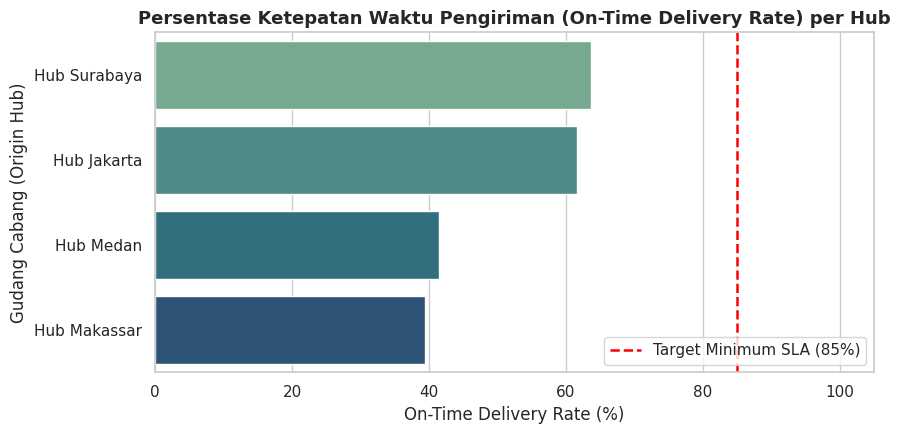

,Origin_Hub,Total_Pengiriman,Jumlah_Terlambat,Rata_Total_Lead_Time,On_Time_Rate_Pct,Late_Rate_Pct
3,Hub Surabaya,1395,507,4.008602,63.66,36.34
0,Hub Jakarta,1742,669,4.028990,61.60,38.40
2,Hub Medan,802,469,4.773067,41.52,58.48
1,Hub Makassar,561,340,4.776292,39.39,60.61


In [4]:
hub_perf = df_logistics.groupby('Origin_Hub').agg(
    Total_Pengiriman=('Shipment_ID', 'count'),
    Jumlah_Terlambat=('Delivery_Status', lambda x: (x == 'Delayed (Terlambat)').sum()),
    Rata_Total_Lead_Time=('Total_Lead_Time_Days', 'mean')
).reset_index()

hub_perf['On_Time_Rate_Pct'] = ((1 - (hub_perf['Jumlah_Terlambat'] / hub_perf['Total_Pengiriman'])) * 100).round(2)
hub_perf['Late_Rate_Pct'] = (100 - hub_perf['On_Time_Rate_Pct']).round(2)
hub_perf = hub_perf.sort_values(by='On_Time_Rate_Pct', ascending=False)

plt.figure(figsize=(9, 4.5))
sns.barplot(
    data=hub_perf,
    x='On_Time_Rate_Pct',
    y='Origin_Hub',
    hue='Origin_Hub',
    palette='crest',
    legend=False
)
plt.axvline(85, color='red', linestyle='--', linewidth=1.8, label='Target Minimum SLA (85%)')
plt.title('Persentase Ketepatan Waktu Pengiriman (On-Time Delivery Rate) per Hub', fontsize=13, fontweight='bold')
plt.xlabel('On-Time Delivery Rate (%)')
plt.ylabel('Gudang Cabang (Origin Hub)')
plt.xlim(0, 105)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('sla_per_hub.png', dpi=300)
plt.show()

display(hub_perf)

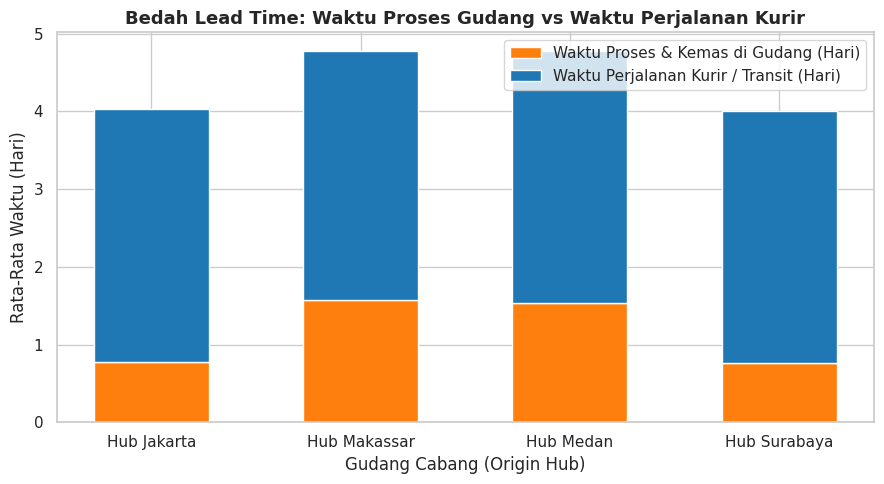

,Origin_Hub,Warehouse_Prep_Days,Transit_Days
0,Hub Jakarta,0.77,3.26
1,Hub Makassar,1.57,3.20
2,Hub Medan,1.54,3.23
3,Hub Surabaya,0.76,3.25


In [5]:
bottleneck = df_logistics.groupby('Origin_Hub')[['Warehouse_Prep_Days', 'Transit_Days']].mean().reset_index()

# Membuat Stacked Bar Chart untuk membandingkan Waktu Gudang vs Waktu Jalan
plt.figure(figsize=(9, 5))
plt.bar(bottleneck['Origin_Hub'], bottleneck['Warehouse_Prep_Days'], label='Waktu Proses & Kemas di Gudang (Hari)', color='#ff7f0e', width=0.55)
plt.bar(bottleneck['Origin_Hub'], bottleneck['Transit_Days'], bottom=bottleneck['Warehouse_Prep_Days'], label='Waktu Perjalanan Kurir / Transit (Hari)', color='#1f77b4', width=0.55)

plt.title('Bedah Lead Time: Waktu Proses Gudang vs Waktu Perjalanan Kurir', fontsize=13, fontweight='bold')
plt.xlabel('Gudang Cabang (Origin Hub)')
plt.ylabel('Rata-Rata Waktu (Hari)')
plt.legend()
plt.tight_layout()
plt.savefig('bottleneck_leadtime.png', dpi=300)
plt.show()

display(bottleneck.round(2))

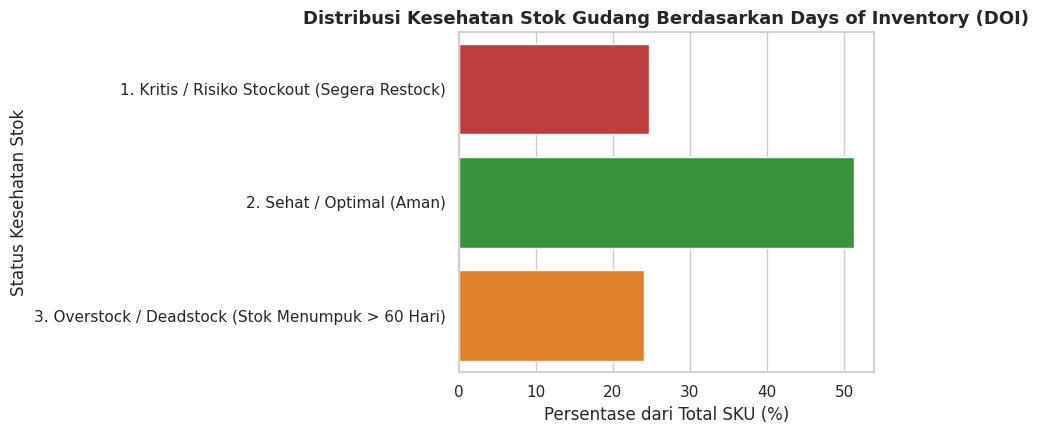

,Inventory_Status,Jumlah_SKU,Total_Unit_Tersimpan,Rata_Days_of_Inventory,Persentase_SKU (%)
0,1. Kritis / Risiko Stockout (Segera Restock),37,7887,8.6,24.7
1,2. Sehat / Optimal (Aman),77,50238,32.5,51.3
2,3. Overstock / Deadstock (Stok Menumpuk > 60 H...,36,31213,134.7,24.0


In [6]:
# Membuat data 150 SKU (Kode Barang) di Gudang
n_sku = 150
df_inventory = pd.DataFrame({
    'SKU_ID': [f'SKU-{100 + i}' for i in range(n_sku)],
    'Product_Line': np.random.choice(['Fast Moving Consumer Goods', 'Elektronik Rumah', 'Perlengkapan Dapur', 'Aksesoris Harian'], size=n_sku),
    'Current_Stock_Units': np.random.randint(20, 1200, size=n_sku),
    'Avg_Daily_Sales': np.random.uniform(2, 35, size=n_sku).round(1),
    'Supplier_Restock_Lead_Time': np.random.choice([7, 14, 21], size=n_sku)
})

# Menghitung Days of Inventory (Stok saat ini cukup untuk berapa hari?)
df_inventory['Days_of_Inventory'] = (df_inventory['Current_Stock_Units'] / df_inventory['Avg_Daily_Sales']).round(1)

# Mengelompokkan status kesehatan stok
def klasifikasi_stok(row):
    if row['Days_of_Inventory'] < row['Supplier_Restock_Lead_Time']:
        return '1. Kritis / Risiko Stockout (Segera Restock)'
    elif row['Days_of_Inventory'] <= 60:
        return '2. Sehat / Optimal (Aman)'
    else:
        return '3. Overstock / Deadstock (Stok Menumpuk > 60 Hari)'

df_inventory['Inventory_Status'] = df_inventory.apply(klasifikasi_stok, axis=1)

inv_summary = df_inventory.groupby('Inventory_Status').agg(
    Jumlah_SKU=('SKU_ID', 'count'),
    Total_Unit_Tersimpan=('Current_Stock_Units', 'sum'),
    Rata_Days_of_Inventory=('Days_of_Inventory', 'mean')
).reset_index()

inv_summary['Persentase_SKU (%)'] = (inv_summary['Jumlah_SKU'] / n_sku * 100).round(1)

plt.figure(figsize=(9, 4.5))
sns.barplot(
    data=inv_summary,
    x='Persentase_SKU (%)',
    y='Inventory_Status',
    hue='Inventory_Status',
    palette=['#d62728', '#2ca02c', '#ff7f0e'],
    legend=False
)
plt.title('Distribusi Kesehatan Stok Gudang Berdasarkan Days of Inventory (DOI)', fontsize=13, fontweight='bold')
plt.xlabel('Persentase dari Total SKU (%)')
plt.ylabel('Status Kesehatan Stok')
plt.tight_layout()
plt.savefig('inventory_status.png', dpi=300)
plt.show()

display(inv_summary.round(1))